**Task 3: Customer Segmentation (Unsupervised Learning)**
• Tech Stack: Python, Scikit-Learn (K-Means, DBSCAN), Plotly
• Description: Apply clustering algorithms to unlabeled customer data (e.g., browsing behavior, enquiry
frequency) to discover hidden customer segments. Visualize these clusters in 3D space to inform targeted
marketing strategies.

**1 Install and import libraries**

In [ ]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn plotly

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


**2. Generate customer dataset (1000 records)**

In [ ]:
np.random.seed(42)

n = 1000

data = {
    'Customer_ID': range(1, n + 1),
    'Age': np.random.randint(18, 65, n),
    'Annual_Income': np.random.randint(15000, 120000, n),
    'Browsing_Time': np.random.randint(1, 100, n),
    'Enquiry_Frequency': np.random.randint(1, 30, n),
    'Purchase_Frequency': np.random.randint(1, 20, n),
    'Spending_Score': np.random.randint(1, 101, n)
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset created successfully!
   Customer_ID  Age  Annual_Income  Browsing_Time  Enquiry_Frequency  \
0            1   56          20287              3                 26   
1            2   46          49387             28                  4   
2            3   32          23512             74                  7   
3            4   60          16342             35                  7   
4            5   25          78076             61                 18   

   Purchase_Frequency  Spending_Score  
0                   7              79  
1                   7               5  
2                   3              60  
3                   1              46  
4                   4              50  

Dataset Shape: (1000, 7)


**3. Save and download dataset**

In [ ]:
df.to_csv('customer_segmentation_dataset.csv', index=False)

from google.colab import files
files.download('customer_segmentation_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**4. Data preprocessing
Select the numerical features and normalize the data using StandardScaler. bold text**

In [ ]:
features = [
    'Age',
    'Annual_Income',
    'Browsing_Time',
    'Enquiry_Frequency',
    'Purchase_Frequency',
    'Spending_Score'
]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data preprocessing completed!")

Data preprocessing completed!


**5. Find optimal clusters using Elbow Method**

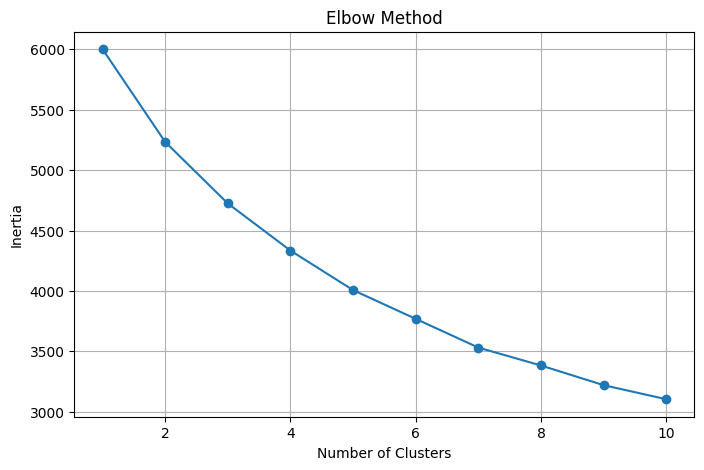

In [ ]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

**6. Apply K-Means clustering**

In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")
print(df['KMeans_Cluster'].value_counts().sort_index())

K-Means Clustering Completed!
KMeans_Cluster
0    214
1    281
2    257
3    248
Name: count, dtype: int64


**7. Apply DBSCAN clustering**

In [ ]:
dbscan = DBSCAN(  eps=1.5,  min_samples=8)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("DBSCAN Clustering Completed!")

print(df['DBSCAN_Cluster'].value_counts().sort_index())

noise = (df['DBSCAN_Cluster'] == -1).sum()

print("Noise / Outlier Customers:", noise)

DBSCAN Clustering Completed!
DBSCAN_Cluster
-1      2
 0    998
Name: count, dtype: int64
Noise / Outlier Customers: 2


**8. 3D visualization using Plotly – K-Means**

In [ ]:
fig = px.scatter_3d( df,
    x='Annual_Income',
    y='Spending_Score',
    z='Browsing_Time',
    color='KMeans_Cluster',
    hover_data=['Customer_ID', 'Age', 'Enquiry_Frequency'],
    title='3D Customer Segmentation Using K-Means',
    labels={
        'KMeans_Cluster': 'Customer Segment'
    }
)

fig.show()

**9. 3D visualization using Plotly – DBSCAN**

In [ ]:
fig = px.scatter_3d(
    df,
    x='Annual_Income',
    y='Spending_Score',
    z='Browsing_Time',
    color='DBSCAN_Cluster',
    hover_data=['Customer_ID', 'Age'],
    title='3D Customer Segmentation Using DBSCAN'
)

fig.show()

**10. Customer segment analysis**

In [ ]:
segment_analysis = df.groupby('KMeans_Cluster').agg({
    'Age': 'mean',
    'Annual_Income': 'mean',
    'Browsing_Time': 'mean',
    'Enquiry_Frequency': 'mean',
    'Purchase_Frequency': 'mean',
    'Spending_Score': 'mean',
    'Customer_ID': 'count'
}).round(2)

segment_analysis.rename(
    columns={'Customer_ID': 'Total_Customers'},
    inplace=True
)

print("Customer Segment Analysis")
display(segment_analysis)

Customer Segment Analysis


,Age,Annual_Income,Browsing_Time,Enquiry_Frequency,Purchase_Frequency,Spending_Score,Total_Customers
KMeans_Cluster,,,,,,,
0,38.12,38728.95,61.91,7.71,12.01,57.03,214
1,41.93,70805.60,44.05,19.79,11.47,22.25,281
2,41.67,95336.02,38.84,9.24,9.01,56.36,257
3,41.68,55916.72,50.08,22.56,7.72,72.10,248


**11. Compare K-Means and DBSCAN**

In [ ]:
print("K-Means Number of Clusters:",
      df['KMeans_Cluster'].nunique())

print("DBSCAN Number of Clusters:",
      len(set(df['DBSCAN_Cluster']) - {-1}))

print("DBSCAN Noise Points:",
      (df['DBSCAN_Cluster'] == -1).sum())

kmeans_score = silhouette_score(X_scaled, df['KMeans_Cluster'])

print("\nK-Means Silhouette Score:", round(kmeans_score, 3))

dbscan_labels = df['DBSCAN_Cluster']

valid = dbscan_labels != -1

if len(set(dbscan_labels[valid])) > 1:
    score = silhouette_score(
        X_scaled[valid],
        dbscan_labels[valid]
    )
    print("DBSCAN Silhouette Score:", round(score, 3))
else:
    print("DBSCAN Silhouette Score: Not applicable")

K-Means Number of Clusters: 4
DBSCAN Number of Clusters: 1
DBSCAN Noise Points: 2

K-Means Silhouette Score: 0.124
DBSCAN Silhouette Score: Not applicable


**12. Marketing strategy for customer segments**

In [ ]:
def marketing_strategy(score):
    if score >= 75:
        return "Premium Offers and Loyalty Rewards"
    elif score >= 50:
        return "Special Discounts and Product Recommendations"
    elif score >= 25:
        return "Engagement Campaigns and Personalized Offers"
    else:
        return "Attractive Introductory Offers"

df['Marketing_Strategy'] = df['Spending_Score'].apply(
    marketing_strategy
)

display(df[[
    'Customer_ID',
    'Annual_Income',
    'Spending_Score',
    'KMeans_Cluster',
    'Marketing_Strategy'
]].head(20))

,Customer_ID,Annual_Income,Spending_Score,KMeans_Cluster,Marketing_Strategy
0,1,20287,79,3,Premium Offers and Loyalty Rewards
1,2,49387,5,1,Attractive Introductory Offers
2,3,23512,60,0,Special Discounts and Product Recommendations
3,4,16342,46,0,Engagement Campaigns and Personalized Offers
4,5,78076,50,3,Special Discounts and Product Recommendations
5,6,34216,48,0,Engagement Campaigns and Personalized Offers
6,7,108070,6,2,Attractive Introductory Offers
7,8,94767,89,3,Premium Offers and Loyalty Rewards
8,9,112829,56,3,Special Discounts and Product Recommendations
9,10,41614,59,0,Special Discounts and Product Recommendations


**13. Export final results**

In [ ]:
df.to_csv(
    'Customer_Segmentation_Final_Results.csv',
    index=False
)

files.download('Customer_Segmentation_Final_Results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**14. Display final visualization**

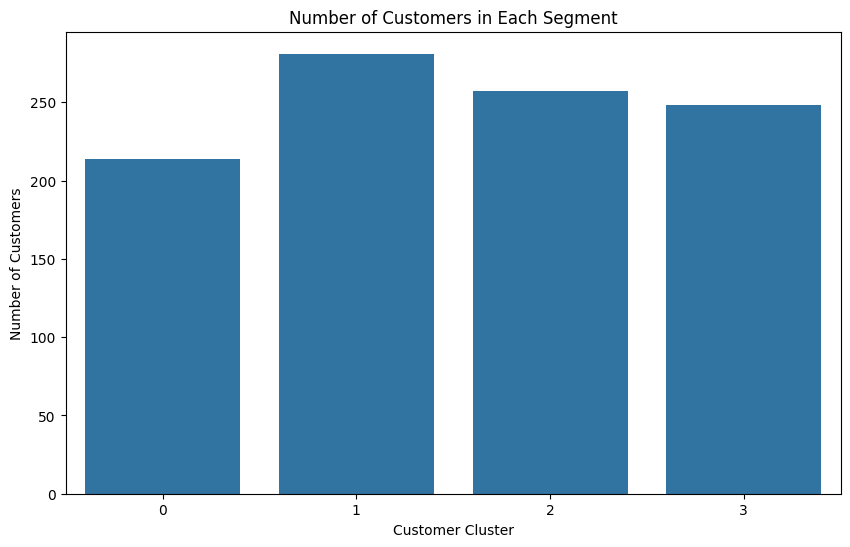

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='KMeans_Cluster'
)

plt.title('Number of Customers in Each Segment')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()